# Tâche 2 : Question-réponse avec poursuite du pré-entraînement du modèle génératif

Cette tâche consiste à poursuivre le préentraînement d'un modèle pré‑entraîné sur un corpus de petite taille. On vous demande d'évaluer la qualité des réponses du modèle après avoir complété l'entraînement supplémentaire. L'évaluation du modèle est effectué avec les mêmes paires **questions-réponses** que la tâche 1.

NOTE: Il est important de sauvegarder le modèle pré-entraîné dans cette tâche (ainsi que le tokenizer) car vous les réutilisez à la tâche 3.

> Il est recommandé de faire ce travail pratique en utilisant une carte graphique GPU compatible avec HuggingFace/Pytorch.
> Si votre machine n’en possède pas, vous pouvez utiliser **Google Colab** pour exécuter le *notebook* dans le cloud.

In [ ]:
# Vérification de l'environnement
import os
import torch

if torch.cuda.is_available():
    print("GPU disponible :", torch.cuda.get_device_name(0))
else:
    print("Pas de GPU : l'inférence se fera sur CPU (plus lent).")
    print("Pour activer le GPU : Exécution > Modifier le type d'exécution > GPU T4")

print("Fichier trouvé :", os.path.exists("data/test_questions.json"))

Mounted at /content/drive
/content/drive/MyDrive/Tp2
GPU disponible : Tesla T4
Fichier trouvé : True


## 1. Chargement du modèle Hugging Face et du tokenizer

In [ ]:
model_name = "EleutherAI/pythia-410m"

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

Device : cuda


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float32
).to(device)
print(f"Nombre de paramètres : {model.num_parameters()/1e6:.0f} M")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  911MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Nombre de paramètres : 405 M


## 2. Fonctions de test question-réponse

In [ ]:
def build_prompt(question):
    """Construit le prompt à partir d'une question."""
    return f"Question: {question}\nAnswer:"

In [ ]:
def generate_answer(question, model, tokenizer, max_new_tokens=100):
    """Génère une réponse et retourne uniquement le texte produit après le prompt."""
    prompt = build_prompt(question)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False, # décodage glouton : résultats reproductibles
            repetition_penalty=1.2, # limite les boucles de répétition
            pad_token_id=tokenizer.eos_token_id,
        )
    # On garde seulement les nouveaux jetons (sans prompt)
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True)
    # On coupe si le modèle enchaîne sur une nouvelle question
    answer = answer.split("\nQuestion:")[0].split("\n\n")[0]
    return answer.strip()

In [ ]:
q = "What is Mixture of Experts (MoE) and what type of machine learning technique is it?"
print("Q :", q)
print("R :", generate_answer(q, model, tokenizer))

Q : What is Mixture of Experts (MoE) and what type of machine learning technique is it?
R : It's a combination of two techniques. The first one is called "mixture" or "mixing". This means that the model has been trained with different data sets, but they are all from the same source. For example, if you have training set A1 and test set B2 then your model will be able to predict whether an event happened in both cases. If this happens, we say that our model can distinguish between these events. In other words, there is no difference between them


## 3. Poursuite du pré-entraînement du modèle

In [ ]:
train_fn = "data/train_texts.json"

In [ ]:
import json

with open(train_fn, "r", encoding="utf-8") as f:
    train_data = json.load(f)

lst_texte = []
for item in train_data:
    lst_texte.append(item["text"])


In [ ]:
lst_tokenized_texte = []

for item in lst_texte:
  encoder = tokenizer(item)
  lst_tokenized_texte.append(len(encoder["input_ids"]))

print("Nombre de passages :", len(lst_tokenized_texte))
print("Longueur min       :", min(lst_tokenized_texte), "tokens")
print("Longueur max       :", max(lst_tokenized_texte), "tokens")
print("Longueur moyenne   :", round(sum(lst_tokenized_texte) / len(lst_tokenized_texte), 1), "tokens")
print("Total              :", sum(lst_tokenized_texte), "tokens")

Nombre de passages : 747
Longueur min       : 15 tokens
Longueur max       : 245 tokens
Longueur moyenne   : 133.2 tokens
Total              : 99515 tokens


In [ ]:
from datasets import Dataset
dataset_texte = Dataset.from_dict({"text":lst_texte})

dict_split_dataset = dataset_texte.train_test_split(test_size = 0.1, seed = 20)

def tokenize_function(examples):
    textes = [texte + tokenizer.eos_token for texte in examples["text"]]
    return tokenizer(textes)

dataset_texte_tokenized = dict_split_dataset.map(tokenize_function, batched=True, remove_columns = ["text"])

print(dataset_texte_tokenized)

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

Map:   0%|          | 0/75 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 672
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 75
    })
})


In [ ]:
from itertools import chain

block_size = 256

def group_texts(examples):
  resultat_= {}

  for cle in examples.keys():

    sequence = list(chain(*examples[cle]))

    total_length = len(sequence)
    total_length = (total_length // block_size) * block_size

    blocs = []

    for i in range (0, total_length, block_size):
      blocs.append(sequence[i : i + block_size])
    resultat_[cle] = blocs

  return resultat_


lm_datasets = dataset_texte_tokenized.map(group_texts, batched=True)

print(lm_datasets)

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

Map:   0%|          | 0/75 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 353
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 38
    })
})


In [ ]:
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments
training_args = TrainingArguments(
        output_dir="/content/t2_checkpoints",
    num_train_epochs=3,
    learning_rate=2e-5,
    logging_steps=6,
    eval_steps=10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="steps",
    save_strategy="steps",
    save_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    fp16=True,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset = lm_datasets['train'],
    eval_dataset=lm_datasets['test'],
    processing_class=tokenizer,
    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm = False)
)




In [ ]:
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.


Step,Training Loss,Validation Loss
10,3.415989,3.267469
20,3.181252,3.185673
30,3.140912,3.133120
40,3.125299,3.087692
50,2.847958,3.075054
60,2.440934,3.132883
70,2.379792,3.095354
80,2.338005,3.091920
90,2.430519,3.082316
100,1.972156,3.169090


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.weight'].
[transformers] There were unexpected keys in the checkpoint model loaded: ['embed_out.weight'].


TrainOutput(global_step=135, training_loss=2.513621037094681, metrics={'train_runtime': 216.2312, 'train_samples_per_second': 4.898, 'train_steps_per_second': 0.624, 'total_flos': 575536528097280.0, 'train_loss': 2.513621037094681, 'epoch': 3.0})

In [ ]:
# On doit faire une correction avec le paramètre load_best_model_at_end on va chercher le
# meillleur checkpoint.

best_ckpt = trainer.state.best_model_checkpoint
model = AutoModelForCausalLM.from_pretrained(best_ckpt, dtype=torch.float32).to(device)

eval_trainer = Trainer(
    model=model,
    args=training_args,
    eval_dataset=lm_datasets["test"],
    processing_class=tokenizer,
    data_collator=DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False),
)
print("Meilleur checkpoint rechargé :", best_ckpt)
print("best_metric attendu          :", trainer.state.best_metric)
print(eval_trainer.evaluate())

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Meilleur checkpoint rechargé : /content/t2_checkpoints/checkpoint-50
best_metric attendu          : 3.075054407119751


Training Loss,Validation Loss,Step
No log,3.075054,0


{'eval_loss': 3.075054407119751}


In [ ]:
print("Meilleur checkpoint :", trainer.state.best_model_checkpoint)
print("Meilleure eval_loss :", trainer.state.best_metric)
trainer.evaluate()

Meilleur checkpoint : /content/t2_checkpoints/checkpoint-50
Meilleure eval_loss : 3.075054407119751


Training Loss,Validation Loss,Step
1.885704,3.071520,135


{'eval_loss': 3.071519613265991}

In [ ]:
save_dir = "pythia-410m-t2"

model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

print("Modèle et tokenizer sauvegardés dans", os.path.abspath(save_dir))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle et tokenizer sauvegardés dans /content/drive/MyDrive/Tp2/pythia-410m-t2


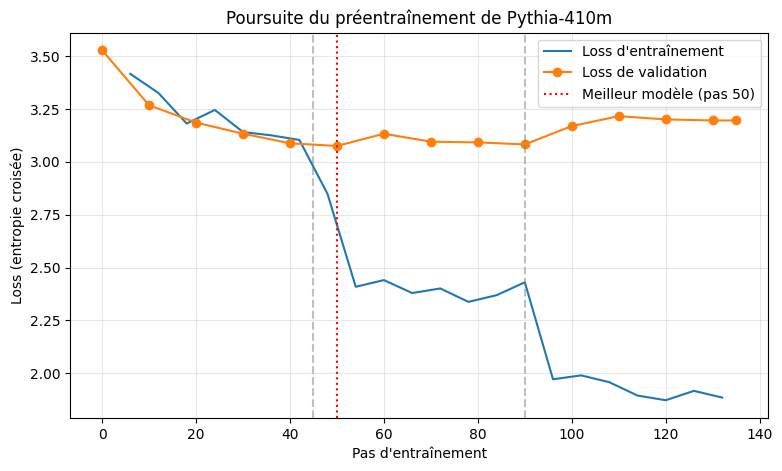

In [ ]:
import matplotlib.pyplot as plt

historique = trainer.state.log_history

logs_train = [d for d in historique if "loss" in d]
logs_eval = [d for d in historique if "eval_loss" in d]

pas_vus = set()
logs_eval_entrainement = []
for d in logs_eval:
    if d["step"] not in pas_vus:
        pas_vus.add(d["step"])
        logs_eval_entrainement.append(d)
logs_eval = logs_eval_entrainement


steps_train = [d["step"] for d in logs_train]
loss_train  = [d["loss"] for d in logs_train]

loss_initiale = 3.5277
steps_eval = [0] + [d["step"] for d in logs_eval]
loss_eval  = [loss_initiale] + [d["eval_loss"] for d in logs_eval]


plt.figure(figsize=(9, 5))
plt.plot(steps_train, loss_train, label="Loss d'entraînement")
plt.plot(steps_eval, loss_eval, marker="o", label="Loss de validation")

for fin_epoque in [45, 90]:
    plt.axvline(fin_epoque, color="gray", linestyle="--", alpha=0.5)

meilleur_pas = int(trainer.state.best_model_checkpoint.split("-")[-1])
plt.axvline(meilleur_pas, color="red", linestyle=":",
            label=f"Meilleur modèle (pas {meilleur_pas})")

plt.xlabel("Pas d'entraînement")
plt.ylabel("Loss (entropie croisée)")
plt.title("Poursuite du préentraînement de Pythia-410m")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("results/t2_courbe_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Génération de réponses avec le nouveau modèle

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(save_dir)
model = AutoModelForCausalLM.from_pretrained(
    save_dir,
    dtype=torch.float16,
).to(device)
model.eval()
print("Modèle rechargé depuis", save_dir)

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Modèle rechargé depuis pythia-410m-t2


In [ ]:
test_fn = "data/test_questions.json"

In [ ]:
import json
from tqdm.auto import tqdm

with open(test_fn, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print(f"{len(test_data)} questions chargées")

model.eval()
results = []
for item in tqdm(test_data):
    generated = generate_answer(item["question"], model, tokenizer)
    results.append({
        "question": item["question"],
        "reference": item["answer"],
        "generated": generated,
    })

# Aperçu des 3 premières réponses
for r in results[:3]:
    print("Q :", r["question"])
    print("R :", r["generated"])
    print("-" * 80)

50 questions chargées


  0%|          | 0/50 [00:00<?, ?it/s]

Q : What is the context window size of GPT-3?
R : The default value for this parameter is 256. This means that when a user opens an image, it will be displayed in a small window with a maximum width and height of 128 pixels (256 bytes). When asked to open another image, the system would display its full content on screen at once without any delay. In contrast, OpenAI's model can only show one or two images before being paused by the human operator until they are shown again. It also has a limited memory capacity which limits how much
--------------------------------------------------------------------------------
Q : Explain what is a transformer architecture.
R : A transformers are an algorithm that can be applied to any input sequence, and produces output sequences of length n. The most common form of transformers used in natural language processing (NLP) today include the feedforward network, recurrent neural networks, attention mechanism, self-attention mechanism, and gating mechan

In [ ]:
output_fn = "results/t2_answers.json"
with open(output_fn, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Réponses sauvegardées dans", output_fn)

Réponses sauvegardées dans t2_answers.json


## 5. Évaluation des résultats

Vous pouvez réutiliser le code d'évaluation rendu disponible pour la tâche 1.

In [ ]:
import string
import re
from collections import Counter

def remove_articles(text):
    return re.sub(r'\b(a|an|the)\b', ' ', text)

def white_space_fix(text):
    return ' '.join(text.split())

def remove_punc(text):
    exclude = set(string.punctuation)
    return ''.join(ch for ch in text if ch not in exclude)

def lower(text):
    return text.lower()

def normalize_answer(s):
    """Mettre en minuscule et retirer la ponctuation, des déterminants and les espaces."""
    return white_space_fix(remove_articles(remove_punc(lower(s))))

In [ ]:
def evaluate_f1(ground_truth, prediction):
    """Normalise les 2 textes, trouve ce qu'il y a en commun et estime précision, rappel et F1."""
    prediction_tokens = normalize_answer(prediction).split()
    ground_truth_tokens = normalize_answer(ground_truth).split()
    common = Counter(prediction_tokens) & Counter(ground_truth_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0.0, 0.0, 0.0
    precision = 1.0 * num_same / len(prediction_tokens)
    recall = 1.0 * num_same / len(ground_truth_tokens)
    f1 = (2 * precision * recall) / (precision + recall)
    return precision, recall, f1

In [ ]:
import pandas as pd

for r in results:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 80)
df[["question", "generated", "precision", "recall", "f1"]]

,question,generated,precision,recall,f1
0,What is the context window size of GPT-3?,The default value for this parameter is 256. This means that when a user ope...,0.036585,0.375000,0.066667
1,Explain what is a transformer architecture.,"A transformers are an algorithm that can be applied to any input sequence, a...",0.142857,0.409091,0.211765
2,Define what is a generative pre-trained transformer (GPT).,"A GPT is an unnormalized, self-attention mechanism that takes input vectors ...",0.173333,0.433333,0.247619
3,Which sources comprise the weighted pre-training dataset for GPT-3?,"The weights are computed by a linear transformer. This is done in two steps,...",0.038961,0.214286,0.065934
4,List the three main classes of language modelling tasks discussed in the con...,The transformer is a multi-head attention mechanism. It consists of two part...,0.013333,0.111111,0.023810
5,What is knowledge distillation in the context of transformer models?,It's a technique used to train large language model (LLM) systems by trainin...,0.132530,0.354839,0.192982
6,What is GPT-4 and who developed it?,"It was created by the OpenAI team in 2026. The first version of GPT-4, relea...",0.140625,0.529412,0.222222
7,In what year was GPT-4 released in ChatGPT?,It is available on the Google Code repository. The release date of GPT-4 is ...,0.044776,0.428571,0.081081
8,Describe what is multimodal capability in the context of GPT-4?,It can be seen as a combination of both. The first step is to train an encod...,0.093333,0.269231,0.138614
9,On what date was GPT-4 training completed?,The first day of the month. It is not clear whether this occurred on a speci...,0.011905,0.142857,0.021978


In [ ]:
print("Moyennes sur", len(df), "questions")
print("="*25)
print(f"Précision : {df['precision'].mean():.3f}")
print(f"Rappel    : {df['recall'].mean():.3f}")
print(f"F1        : {df['f1'].mean():.3f}")

print("\n 3 meilleures réponses (F1)")
print("="*25)
for _, r in df.nlargest(3, "f1").iterrows():
    print(f"[F1={r['f1']:.2f}] Q : {r['question']}")
    print("   Réf :", r["reference"])
    print("   Gén :", r["generated"], "\n")

print("3 pires réponses (F1)")
print("="*25)
for _, r in df.nsmallest(3, "f1").iterrows():
    print(f"[F1={r['f1']:.2f}] Q : {r['question']}")
    print("   Réf :", r["reference"])
    print("   Gén :", r["generated"], "\n")

Moyennes sur 50 questions
Précision : 0.079
Rappel    : 0.305
F1        : 0.120

 3 meilleures réponses (F1)
[F1=0.27] Q : What is reinforcement learning from human feedback (RLHF)?
   Réf : RLHF is a technique to align an intelligent agent with human preferences. It involves training a reward model to represent preferences from human feedback, which can then be used to train other models through reinforcement learning.
   Gén : It's a process in which humans evaluate the performance of AI systems. The goal is to improve them by making it easier for them to learn and perform better, so that they can be more effective at their tasks. RLHF involves two steps: training an agent to behave like humans; then evaluating its behavior against human feedback. This allows agents to adapt to new situations without having to change how they operate or train themselves. In practice, this requires large amounts of data about the environment, including both natural 

[F1=0.26] Q : What are the researc

###Comparaison avec la tâche 1

In [ ]:
# Réponses générées par le modèle d'origine
t1_fn = "results/t1_answers.json"
print("Fichier T1 trouvé :", os.path.exists(t1_fn))

with open(t1_fn, "r", encoding="utf-8") as f:
    results_t1 = json.load(f)

for r in results_t1:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df_t1 = pd.DataFrame(results_t1)


assert list(df_t1["question"]) == list(df["question"]), "Les questions T1 et T2 ne correspondent pas!"
print(len(df_t1), "réponses T1 chargées")

Fichier T1 trouvé : True
50 réponses T1 chargées


In [ ]:
# 1. Moyennes côte à côte
moyennes = pd.DataFrame({
    "T1 (sans adaptation)": df_t1[["precision", "recall", "f1"]].mean(),
    "T2 (préentraînement)": df[["precision", "recall", "f1"]].mean(),
})
moyennes["Différence"] = moyennes.iloc[:, 1] - moyennes.iloc[:, 0]
print("Moyennes sur", len(df), "questions")
print("=" * 25)
print(moyennes.round(3), "\n")

# 2. Différence de F1 question par question
df_comp = pd.DataFrame({
    "question":  df["question"],
    "reference": df["reference"],
    "gen_t1":    df_t1["generated"],
    "gen_t2":    df["generated"],
    "f1_t1":     df_t1["f1"],
    "f1_t2":     df["f1"],
})
df_comp["delta_f1"] = df_comp["f1_t2"] - df_comp["f1_t1"]

print("Questions améliorées :", (df_comp["delta_f1"] > 0).sum())
print("Questions dégradées  :", (df_comp["delta_f1"] < 0).sum())
print("Questions identiques :", (df_comp["delta_f1"] == 0).sum())


def afficher(lignes, titre):
    print("\n" + titre)
    print("=" * 25)
    for _, r in lignes.iterrows():
        print(f"[ΔF1={r['delta_f1']:+.2f}] Q : {r['question']}")
        print("   Réf :", r["reference"])
        print(f"   T1 (F1={r['f1_t1']:.2f}) :", r["gen_t1"])
        print(f"   T2 (F1={r['f1_t2']:.2f}) :", r["gen_t2"], "\n")

afficher(df_comp.nlargest(3, "delta_f1"),  "3 plus grandes progressions")
afficher(df_comp.nsmallest(3, "delta_f1"), "3 plus grandes régressions")

df_comp.to_csv("results/t2_comparaison_t1.csv", index=False)

Moyennes sur 50 questions
           T1 (sans adaptation)  T2 (préentraînement)  Différence
precision                 0.091                 0.079      -0.012
recall                    0.205                 0.305       0.100
f1                        0.107                 0.120       0.013 

Questions améliorées : 29
Questions dégradées  : 19
Questions identiques : 2

3 plus grandes progressions
[ΔF1=+0.26] Q : What are the research areas mentioned within Meta AI's natural language processing work?
   Réf : Meta AI's natural language processing research areas include machine translation, natural language generation, and question answering.
   T1 (F1=0.00) : The following is a list of some of them.
   T2 (F1=0.26) : The following is a list of topics that have been discussed in Meta AI's Natural Language Processing (NLP) lab. These include machine learning, computer vision and image generation, text analysis, natural language understanding, natural-language reasoning, and artificial intel

###Recherche d'hyperparamètres

In [ ]:
import time, gc
import pandas as pd
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments

batch_sizes    = [4, 8, 16, 24]
learning_rates = [1e-5, 2e-5, 5e-5, 1e-4]
collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)
resultats = []

for bs in batch_sizes:
    for lr in learning_rates:
        print(f"===== Batch {bs} | Learning rate {lr} =====")

        model = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.float32).to(device)

        args = TrainingArguments(
            output_dir="/content/t2_recherche", # local
            num_train_epochs=3,
            learning_rate=lr,
            per_device_train_batch_size=bs,
            per_device_eval_batch_size=8,
            eval_strategy="epoch",
            logging_strategy="epoch",
            save_strategy="no",
            fp16=True,
            report_to="none",
            seed=42,
        )
        trainer = Trainer(
            model=model,
            args=args,
            train_dataset=lm_datasets["train"],
            eval_dataset=lm_datasets["test"],
            processing_class=tokenizer,
            data_collator=collator,
        )

        debut = time.time()
        trainer.train()
        duree = (time.time() - debut) / 60


        evals = [d for d in trainer.state.log_history if "eval_loss" in d]
        meilleur = min(evals, key=lambda d: d["eval_loss"])

        resultats.append({
            "Batch": bs,
            "Taux d'apprentissage": lr,
            "Meilleure époque": meilleur["epoch"],
            "Perte de validation": meilleur["eval_loss"],
            "Temps (min)": round(duree, 2),
        })
        pd.DataFrame(resultats).to_csv("results/t2_recherche_partiel.csv", index=False)

        del trainer, model
        gc.collect()
        torch.cuda.empty_cache()

===== Batch 4 | Learning rate 1e-05 =====


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.


Epoch,Training Loss,Validation Loss
1,3.204290,3.071722
2,2.542934,3.071885
3,2.145946,3.148550


===== Batch 4 | Learning rate 2e-05 =====


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

... (54 outputs left out)

===== Batch 24 | Learning rate 0.0001 =====


Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.


Epoch,Training Loss,Validation Loss
1,3.983226,3.264051
2,2.524487,3.193700
3,1.772382,3.317545


In [ ]:
df_recherche = (pd.DataFrame(resultats)
                .sort_values("Perte de validation")
                .reset_index(drop=True))

df_recherche.to_csv("results/t2_recherche_hyperparametres.csv", index=False)

df_recherche.style.format({
    "Taux d'apprentissage": "{:.5f}",
    "Perte de validation": "{:.6f}",
    "Meilleure époque": "{:.1f}",
}).hide(axis="index")

Batch,Taux d'apprentissage,Meilleure époque,Perte de validation,Temps (min)
4,0.00002,1.0,3.066311,0.830000
8,0.00002,1.0,3.066961,0.590000
4,0.00001,1.0,3.071722,0.830000
8,0.00001,2.0,3.076264,0.590000
16,0.00002,2.0,3.082080,0.480000
24,0.00002,2.0,3.087973,0.460000
16,0.00001,2.0,3.093860,0.480000
24,0.00001,3.0,3.103047,0.460000
24,0.00005,2.0,3.109001,0.460000
16,0.00005,1.0,3.124993,0.480000
